# **Project Name — RAAI-SGC 2.0: Auxiliary IT Domain Classification**


##### **Project Type** — NLP / Multiclass Classification (supporting experiment)
##### **Contribution** — Fill in actual team information
##### **Team Member(s)** — *Fill in personally*


# **Project Summary -**

This machine-learning notebook provides an auxiliary supervised-learning experiment for RAAI-SGC 2.0, an IT knowledge assistant that will later combine source retrieval, weighted graph expansion, and a generative large language model. The notebook’s specific prediction task is to assign an IT source passage to one of four collection-domain categories: AI/ML, Cloud & DevOps, Cybersecurity, or Software Engineering. This is distinct from teaching the chatbot to generate answers and distinct from evaluating answer correctness. The classification labels are inherited from the corpus collection procedure rather than independently adjudicated external ground truth.

The unchanged master dataset has **5,206 rows**, but only its **145 SOURCE records** are independent classification examples. The remaining **4,771 EDGE** and **290 QA_DRAFT** records refer back to those sources and must not be treated as extra observations. There are **40 AI/ML**, **32 Cloud & DevOps**, **36 Cybersecurity**, and **37 Software Engineering** documents. The model input is `source_text` alone. Titles, identifiers, splits, graph statistics, question drafts, and review statuses are excluded from predictors because they are not needed for a fair text-only baseline and may introduce leakage or circular performance claims.

The predefined source-level split is preserved: **116 training**, **14 validation**, and **15 held-out test** documents. TF-IDF vectorization is fitted inside each training-only model pipeline. Hyperparameter searches use **three-fold stratified cross-validation** on training examples, without fitting on validation or test passages. Three model families are evaluated: a most-frequent-label DummyClassifier, Complement Naive Bayes with TF-IDF, and a class-weighted Logistic Regression with TF-IDF. Macro-F1 is emphasized because the four classes have unequal numbers of documents, although accuracy and class-level precision and recall are also reported.

In the executed run, the dummy baseline achieves **0.1111 validation macro-F1**. Untuned Complement Naive Bayes obtains **0.7597 macro-F1** and **0.7857 accuracy**; its tuned variant reaches **0.7667 macro-F1**, also with **0.7857 accuracy**. Untuned logistic regression achieves **0.8542 macro-F1** and **0.8571 accuracy**. The tuned logistic regression model is selected on validation, at **0.9365 macro-F1** and **0.9286 accuracy**. The grid search selects **C=0.1** and TF-IDF **unigrams plus bigrams**. These validation values are not test-set estimates.

On the independent **15-document test set**, the selected model achieves **0.8000 accuracy** (12 of 15 correct) and **0.7667 macro-F1**. Per-class recall is **1.00** for AI/ML, **0.33** for Cloud & DevOps, **1.00** for Cybersecurity, and **0.75** for Software Engineering. These uneven outcomes show that a strong small-validation score does not guarantee uniform generalization. With only three Cloud & DevOps test records, each mistake changes its recall substantially. The model is serialized and successfully reloaded for a prediction consistency check.

Exploratory hypothesis tests also indicate domain differences in passage word counts (Kruskal–Wallis **p=0.000404**) and a strong rank association between passage length and graph edge count (Spearman **rho=0.9611**). The domain-versus-split chi-square approximation is unreliable because its minimum expected count is **3.09**. None of these tests demonstrates that graph retrieval improves answer quality.

The experiment therefore supplies a reproducible, leakage-conscious classical ML baseline and an example of controlled model selection. It does not fine-tune an LLM, verify licensing, approve draft questions, or benchmark the live chatbot. Future work requires independently reviewed domain labels, a larger held-out test sample, verified answer-evaluation questions, and separate GraphRAG and QLoRA experiments.

# **GitHub Link -**

**GitHub URL:** Add the repository URL once you publish the actual project.


# **Problem Statement**


Predict the primary IT domain (`ai_ml`, `cloud_devops`, `cybersecurity`, `software_engineering`) of a Wikipedia-based source document from its text. This exercise provides a reproducible ML baseline for the capstone rubric, but domain labels reflect the dataset collection policy, not independent external ground truth. The LLM retrieval research remains a separate question.


# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required. 
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits. 
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule. 

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Colab / local notebook bootstrap. Upload only the RAAI_SGC_EDA_ML_COLAB_ONLY folder to Google Drive.
from pathlib import Path
import os, sys, json, re, csv, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
try:
    import google.colab
    from google.colab import drive
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')
except ImportError:
    pass
PROJECT_NAME = 'RAAI_SGC_EDA_ML_COLAB_COMPLETED'
CANDIDATES = [Path('/content/drive/MyDrive')/PROJECT_NAME,
              Path('/content')/PROJECT_NAME, Path.cwd(), Path.cwd().parent,
              Path('/mnt/data')/PROJECT_NAME]
PROJECT_ROOT = next((p.resolve() for p in CANDIDATES if (p/'data/master.csv').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Upload/extract RAAI_SGC_2_COMPLETE_PROJECT to MyDrive, then rerun this cell; required data/master.csv not found.')
MASTER_CSV = PROJECT_ROOT/'data/master.csv'
REPORT_DIR = PROJECT_ROOT/'reports'
REPORT_DIR.mkdir(parents=True, exist_ok=True)
print('Project:',PROJECT_ROOT, '\nData:',MASTER_CSV)

from collections import Counter
from scipy.stats import chi2_contingency, kruskal, spearmanr
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import joblib
SEED=42
np.random.seed(SEED)

Project: /mnt/data/RAAI_SGC_EDA_ML_COLAB_COMPLETED 
Data: /mnt/data/RAAI_SGC_EDA_ML_COLAB_COMPLETED/data/master.csv


### Dataset Loading

In [2]:
df = pd.read_csv(MASTER_CSV, dtype=str, keep_default_na=False, encoding='utf-8-sig')
required={'record_id','record_type','source_id','domain','split','source_title','source_text','source_url','edge_weight','markov_probability','tfidf_score'}
assert required.issubset(df.columns), f'Missing columns: {required-set(df.columns)}'
sources=df.loc[df.record_type.eq('SOURCE')].copy().drop_duplicates('source_id')
edges=df.loc[df.record_type.eq('EDGE')].copy()
qa=df.loc[df.record_type.eq('QA_DRAFT')].copy()
for name in ('edge_weight','markov_probability','tfidf_score'):
    edges[name]=pd.to_numeric(edges[name],errors='coerce')
sources['text_length']=sources.source_text.str.len()
sources['word_count']=sources.source_text.str.split().str.len()
sources['title_words']=sources.source_title.str.split().str.len()
sources['edge_count']=sources.source_id.map(edges.groupby('source_id').size()).fillna(0).astype(int)
sources['qa_count']=sources.source_id.map(qa.groupby('source_id').size()).fillna(0).astype(int)
sources['avg_edge_weight']=sources.source_id.map(edges.groupby('source_id').edge_weight.mean()).fillna(0)
sources['max_edge_weight']=sources.source_id.map(edges.groupby('source_id').edge_weight.max()).fillna(0)
sources['unique_targets']=sources.source_id.map(edges.groupby('source_id').target_concept.nunique()).fillna(0).astype(int)
sources['license_pending']=sources.license_status.ne('APPROVED')
sources['review_pending']=sources.review_status.ne('APPROVED')
print(f'Total rows={len(df):,}; sources={len(sources):,}; edges={len(edges):,}; draft Q&A={len(qa):,}')
print('This is a source-level analysis. EDGE and QA_DRAFT rows are NOT independent source observations.')

Total rows=5,206; sources=145; edges=4,771; draft Q&A=290
This is a source-level analysis. EDGE and QA_DRAFT rows are NOT independent source observations.


### Dataset First View

In [3]:
display(sources[['source_title','domain','split','word_count']].head())

,source_title,domain,split,word_count
0,A* search algorithm,ai_ml,train,207
47,Vulnerability (computer security),cybersecurity,train,255
91,Intrusion detection system,cybersecurity,train,228
138,Acoustic model,ai_ml,train,70
153,Amazon Elastic Compute Cloud,cloud_devops,train,124


### Dataset Rows & Columns count

In [4]:
print('Master:',df.shape,'Source-level classification:',sources.shape)

Master: (5206, 32) Source-level classification: (145, 42)


### Dataset Information

In [5]:
sources.info()

<class 'pandas.core.frame.DataFrame'>
Index: 145 entries, 0 to 5176
Data columns (total 42 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   record_id            145 non-null    object 
 1   record_type          145 non-null    object 
 2   dataset_version      145 non-null    object 
 3   domain               145 non-null    object 
 4   secondary_domains    145 non-null    object 
 5   source_id            145 non-null    object 
 6   source_title         145 non-null    object 
 7   source_url           145 non-null    object 
 8   source_revision      145 non-null    object 
 9   retrieved_at         145 non-null    object 
 10  source_provider      145 non-null    object 
 11  license_status       145 non-null    object 
 12  review_status        145 non-null    object 
 13  split                145 non-null    object 
 14  concept_id           145 non-null    object 
 15  concept              145 non-null    object 

#### Duplicate Values

In [6]:
print('SOURCE duplicates:',sources.source_id.duplicated().sum()); print('Text hash duplicates:',sources.text_hash.duplicated().sum())

SOURCE duplicates: 0
Text hash duplicates: 0


#### Missing Values/Null Values

In [7]:
print('Empty source text:',sources.source_text.eq('').sum()); print('Empty target labels:',sources.domain.eq('').sum())

Empty source text: 0
Empty target labels: 0


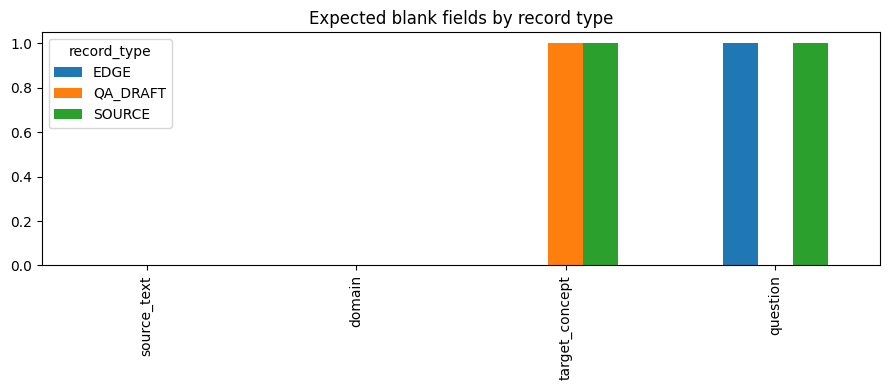

In [8]:
df[['source_text','domain','target_concept','question']].eq('').groupby(df.record_type).mean().T.plot.bar(figsize=(9,4));plt.title('Expected blank fields by record type');plt.tight_layout();plt.show()

### What did you know about your dataset?

**Observed dataset:** 5,206 master rows comprise 145 independent SOURCE examples, 4,771 EDGE rows and 290 QA_DRAFT rows; no duplicate SOURCE identifiers or empty source passages were observed. Domain frequencies are AI/ML 40, Cloud & DevOps 32, Cybersecurity 36 and Software Engineering 37. The predefined 116/14/15 source-level split is retained.

## ***2. Understanding Your Variables***

In [9]:
display(pd.Series(sources.columns, name='SOURCE column names'))

0               record_id
1             record_type
2         dataset_version
3                  domain
4       secondary_domains
5               source_id
6            source_title
7              source_url
8         source_revision
9            retrieved_at
10        source_provider
11         license_status
12          review_status
13                  split
14             concept_id
15                concept
16            source_text
17              text_hash
18         target_concept
19         target_surface
20         evidence_start
21           evidence_end
22     markov_probability
23            tfidf_score
24            edge_weight
25            question_id
26          question_type
27               question
28           answer_draft
29    evidence_source_ids
30         evidence_quote
31                  notes
32            text_length
33             word_count
34            title_words
35             edge_count
36               qa_count
37        avg_edge_weight
38        ma

In [10]:
display(sources[['word_count','text_length','edge_count','unique_targets']].describe().T)

,count,mean,std,min,25%,50%,75%,max
word_count,145.0,178.041379,108.028666,26.0,92.0,156.0,233.0,583.0
text_length,145.0,1203.648276,718.206220,208.0,665.0,1077.0,1588.0,3705.0
edge_count,145.0,32.903448,18.414338,7.0,19.0,30.0,43.0,87.0
unique_targets,145.0,32.903448,18.414338,7.0,19.0,30.0,43.0,87.0


### Variables Description 

**Target:** `domain` (four IT areas). **Input:** `source_text` only. **Identifiers:** `source_id` for leakage control. **Excluded model inputs:** `source_title` (can leak topic directly), `source_id`, `record_type`, `split`, Q&A questions, graph-derived features, reviewer decisions and license fields. Other columns remain for auditing, not prediction.


### Check Unique Values for each variable.

In [11]:
display(pd.DataFrame({col:[sources[col].nunique()] for col in ['domain','split','source_title','source_id']},index=['unique']))

,domain,split,source_title,source_id
unique,4,3,145,145


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
work=sources[['source_id','source_text','domain','split','source_title','word_count','edge_count']].copy()
assert work.source_id.is_unique
assert work.source_text.str.strip().ne('').all()
assert work.split.isin(['train','validation','test']).all()
assert not work.source_id.duplicated().any()
print('Model-ready independent source observations:',len(work))

Model-ready independent source observations: 145


### What all manipulations have you done and insights you found?

Filtered to 145 unique SOURCE documents, checked nonempty text and labels, left original source passages unchanged and excluded the 4,771 EDGE and 290 QA_DRAFT rows from supervised fitting. Median passage length is 156 words; graph properties are audited but not used as classification inputs.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

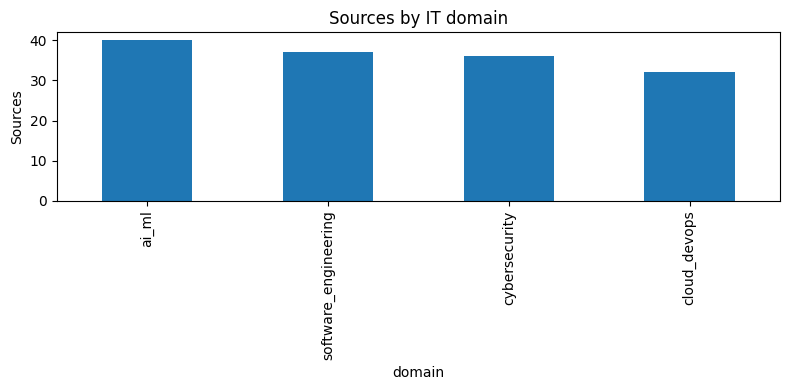

In [13]:
fig, ax = plt.subplots(figsize=(8,4)); sources.domain.value_counts().plot.bar(ax=ax, title='Sources by IT domain'); ax.set_ylabel('Sources'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Coverage across domains** and respects the SOURCE/EDGE/Q&A distinction.


##### 2. What is/are the insight(s) found from the chart?

Across 145 independent SOURCE records, coverage is AI/ML 40 (27.6%), Software Engineering 37 (25.5%), Cybersecurity 36 (24.8%), Cloud & DevOps 32 (22.1%). The largest class has 40 sources and the smallest has 32 (difference: 8); this is fairly balanced but not a random population sample.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

A relatively balanced four-domain source inventory supports a prototype across all requested IT areas, but 145 documents still limit topical depth; prioritize missing concepts rather than asserting market coverage.

#### Chart - 2

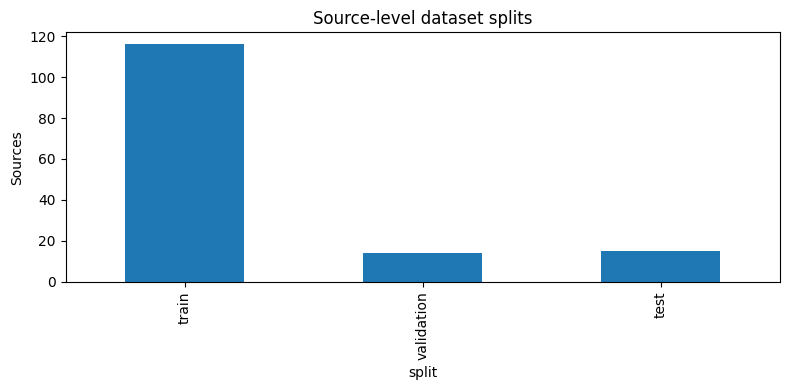

In [14]:
fig, ax = plt.subplots(figsize=(8,4)); sources['split'].value_counts().reindex(['train','validation','test']).plot.bar(ax=ax,title='Source-level dataset splits'); ax.set_ylabel('Sources'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Split balance before model development** and respects the SOURCE/EDGE/Q&A distinction.


##### 2. What is/are the insight(s) found from the chart?

The predefined source split is 116 training (80.0%), 14 validation (9.7%), and 15 test (10.3%) articles. Keeping all EDGE and QA_DRAFT records aligned with their source ID prevents split leakage.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

A source-level holdout supports fairer auxiliary classifier comparisons. Keep validation/test records out of supervised fitting and hyperparameter selection.

#### Chart - 3

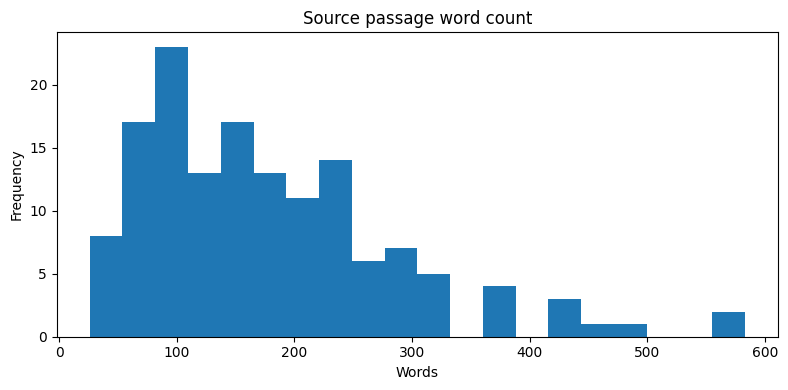

In [15]:
fig, ax = plt.subplots(figsize=(8,4)); sources.word_count.plot.hist(ax=ax,bins=20,title='Source passage word count'); ax.set_xlabel('Words'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Information coverage and short passages** and respects the SOURCE/EDGE/Q&A distinction.


##### 2. What is/are the insight(s) found from the chart?

Source passages contain 26–583 whitespace-separated words (median 156, mean 178.04, first quartile 92, third quartile 233). Very short sources may provide insufficient retrieval context; long passages may need chunking.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Flag passages near the 26-word minimum for completeness checks and consider chunking 583-word passages for context-window efficiency; do not automatically delete them.

#### Chart - 4

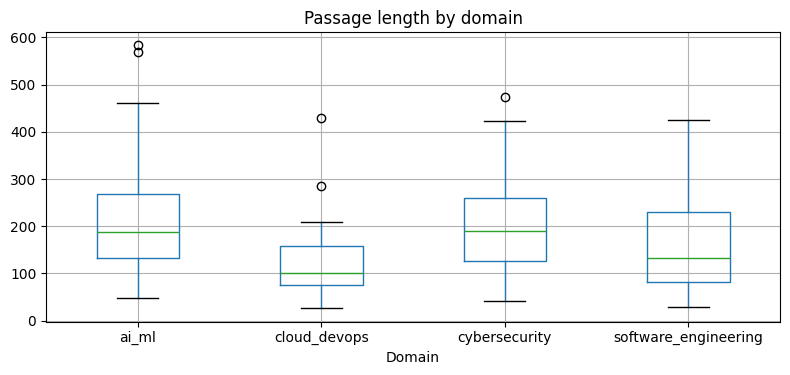

In [16]:
fig, ax = plt.subplots(figsize=(8,4)); sources.boxplot(column='word_count',by='domain',ax=ax); ax.set_title('Passage length by domain'); ax.set_xlabel('Domain'); plt.suptitle(''); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Domain-specific passage length differences** and respects the SOURCE/EDGE/Q&A distinction.


##### 2. What is/are the insight(s) found from the chart?

Median passage lengths differ by domain: AI/ML 188.5 words; Cloud & DevOps 101.0; Cybersecurity 189.5; Software Engineering 133.0. These are descriptive differences, not evidence of downstream model accuracy.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Domain-specific passage-length differences motivate consistent retrieval token budgets; otherwise longer domains may be favored for reasons unrelated to relevance.

#### Chart - 5

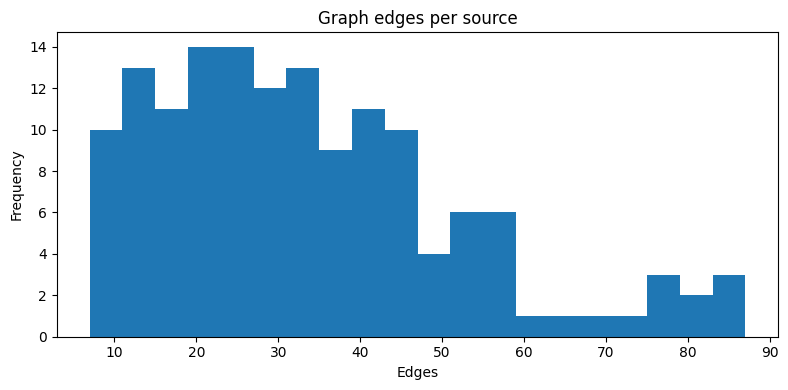

In [17]:
fig, ax = plt.subplots(figsize=(8,4)); sources.edge_count.plot.hist(ax=ax,bins=20,title='Graph edges per source'); ax.set_xlabel('Edges'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Graph density and source connectivity** and respects the SOURCE/EDGE/Q&A distinction.


##### 2. What is/are the insight(s) found from the chart?

Each source yields 7–87 graph edges (median 30, mean 32.90, interquartile range 19–43). Graph density therefore varies substantially and warrants normalization during graph-based ranking.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Consider top-k or normalized edge budgets per source; dense nodes could dominate graph expansion without such controls.

#### Chart - 6

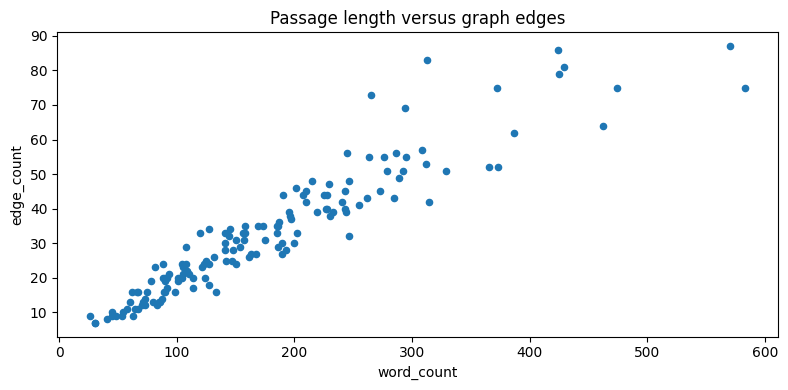

In [18]:
fig, ax = plt.subplots(figsize=(8,4)); sources.plot.scatter(x='word_count',y='edge_count',ax=ax,title='Passage length versus graph edges'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Potential text-length influence on graph size** and respects the SOURCE/EDGE/Q&A distinction.


##### 2. What is/are the insight(s) found from the chart?

Source passage word count and graph edge count are strongly positively correlated (Pearson r=0.937, n=145). This is expected because longer passages offer more opportunities to extract terms; it does not validate semantic relevance.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

A length-driven edge effect means graph counts should not be sold as knowledge quality. Compare against length-aware and vector-only baselines.

#### Chart - 7

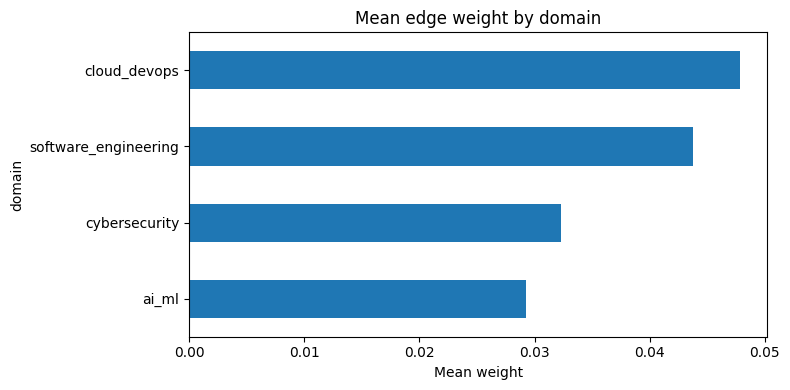

In [19]:
fig, ax = plt.subplots(figsize=(8,4)); edges.groupby('domain').edge_weight.mean().sort_values().plot.barh(ax=ax,title='Mean edge weight by domain'); ax.set_xlabel('Mean weight'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Weighted graph behavior across subdomains** and respects the SOURCE/EDGE/Q&A distinction.


##### 2. What is/are the insight(s) found from the chart?

Mean Markov–TF-IDF edge weights differ by domain: AI/ML 0.0293, Cloud & DevOps 0.0478, Cybersecurity 0.0323, Software Engineering 0.0437. Because weights are normalized within graph construction, cross-domain means must not be interpreted as relative answer correctness.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Use weight statistics to inspect ranking behavior and potential score-calibration differences, then measure Recall@K and answer faithfulness on approved evaluation questions.

#### Chart - 8

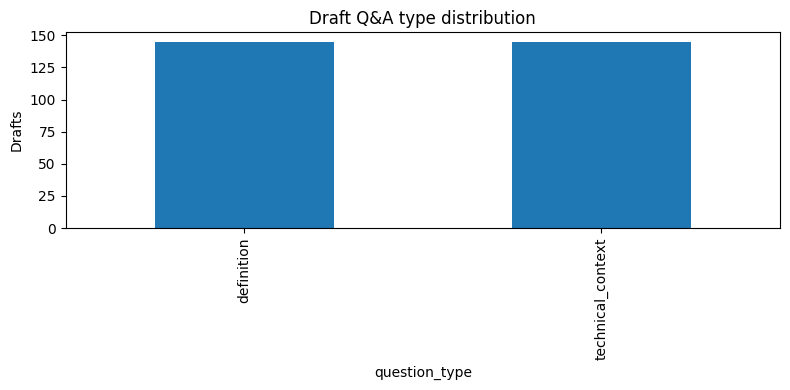

In [20]:
fig, ax = plt.subplots(figsize=(8,4)); qa.question_type.value_counts().plot.bar(ax=ax,title='Draft Q&A type distribution'); ax.set_ylabel('Drafts'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Q&A task diversity** and respects the SOURCE/EDGE/Q&A distinction.


##### 2. What is/are the insight(s) found from the chart?

The draft Q&A inventory contains exactly 145 definition questions and 145 technical-context questions (290 total). All are drafts, so no question is yet an approved supervised training or gold-evaluation label.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

The draft inventory can guide the human review queue, but training and publication must wait for independent evidence review.

#### Chart - 9

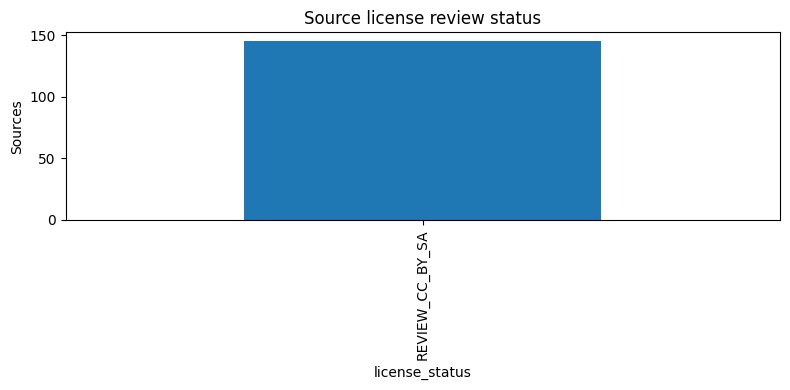

In [21]:
fig, ax = plt.subplots(figsize=(8,4)); sources.license_status.value_counts().plot.bar(ax=ax,title='Source license review status'); ax.set_ylabel('Sources'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Copyright and license audit readiness** and respects the SOURCE/EDGE/Q&A distinction.


##### 2. What is/are the insight(s) found from the chart?

All 145 source records have license_status=REVIEW_CC_BY_SA. This is a review flag, NOT confirmed clearance for public redistribution or supervised model training.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Complete CC BY-SA attribution and licensing review before distribution or training use; the flag indicates a compliance obligation.

#### Chart - 10

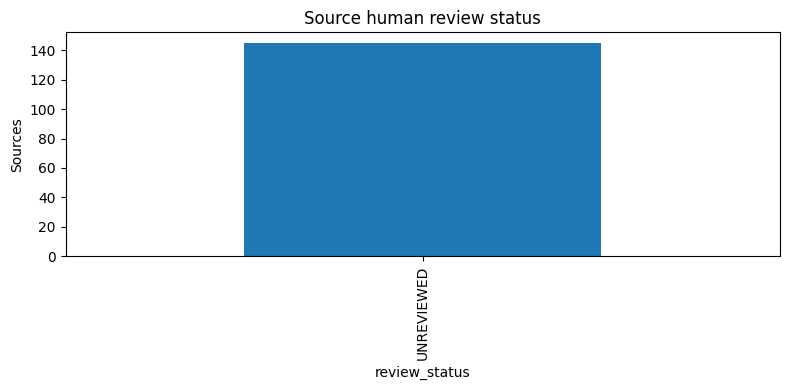

In [22]:
fig, ax = plt.subplots(figsize=(8,4)); sources.review_status.value_counts().plot.bar(ax=ax,title='Source human review status'); ax.set_ylabel('Sources'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Factual review readiness** and respects the SOURCE/EDGE/Q&A distinction.


##### 2. What is/are the insight(s) found from the chart?

All 145 source records have review_status=UNREVIEWED. Engineering checks passed, but human factual and attribution review remains outstanding.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Prioritize human factual review of all source passages, especially those used for chatbot demonstrations and benchmark creation.

#### Chart - 11

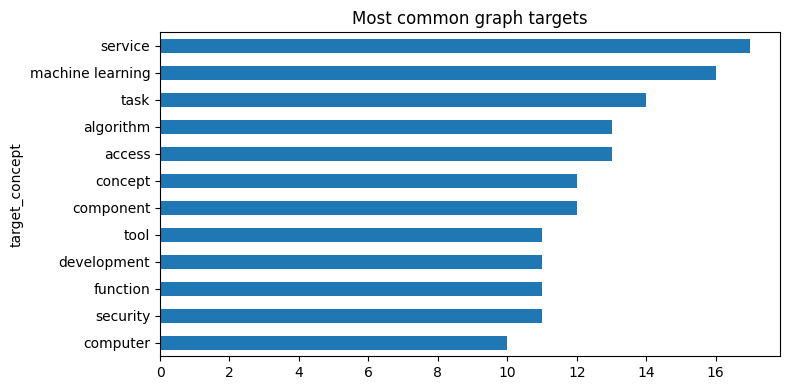

In [23]:
fig, ax = plt.subplots(figsize=(8,4)); edges.target_concept.value_counts().head(12).sort_values().plot.barh(ax=ax,title='Most common graph targets'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Overly frequent generic concepts** and respects the SOURCE/EDGE/Q&A distinction.


##### 2. What is/are the insight(s) found from the chart?

The most repeated graph target is “service” (17 edges), followed by “machine learning” (16) and “task” (14); “access” and “algorithm” appear 13 times each. Generic targets may create noisy expansions, suggesting a specificity filter.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Down-weight overly generic graph targets such as “service” or “task” to reduce cross-domain retrieval noise; validate the choice experimentally.

#### Chart - 12

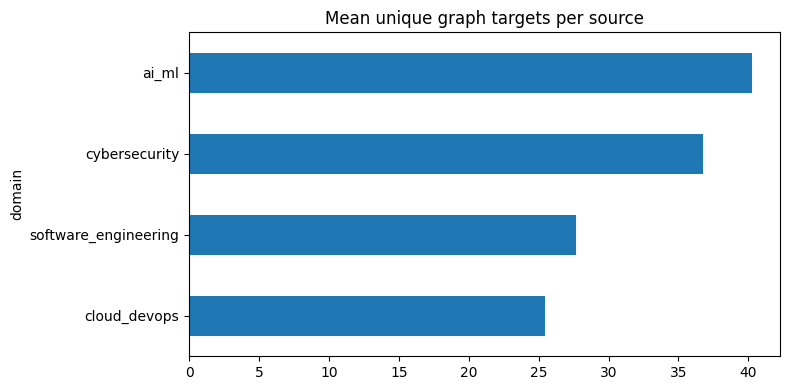

In [24]:
fig, ax = plt.subplots(figsize=(8,4)); sources.groupby('domain').unique_targets.mean().sort_values().plot.barh(ax=ax,title='Mean unique graph targets per source'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Graph concept diversity by domain** and respects the SOURCE/EDGE/Q&A distinction.


##### 2. What is/are the insight(s) found from the chart?

Average distinct graph targets per source: AI/ML 40.25, Cloud & DevOps 25.44, Cybersecurity 36.72, Software Engineering 27.70. The cross-domain difference is influenced by source lengths and extraction rules; it cannot by itself establish retrieval quality.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Domain-wise expansion budgets may reduce dominance of densely connected topics, but must be tested against independently judged queries.

#### Chart - 13

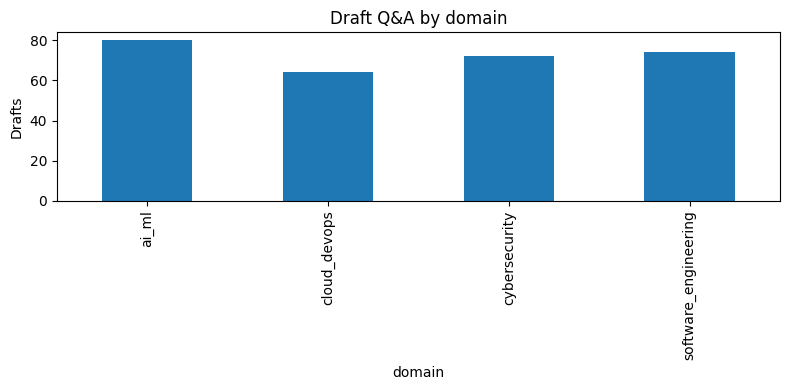

In [25]:
fig, ax = plt.subplots(figsize=(8,4)); sources.groupby('domain').qa_count.sum().plot.bar(ax=ax,title='Draft Q&A by domain'); ax.set_ylabel('Drafts'); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

This chart examines **Q&A balance for future supervised data** and respects the SOURCE/EDGE/Q&A distinction.


##### 2. What is/are the insight(s) found from the chart?

There are exactly two draft questions per source. Draft counts by domain are AI/ML 80, Cloud & DevOps 64, Cybersecurity 72, and Software Engineering 74, mirroring source availability.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Equal drafts per source makes review workload predictable; unequal domain totals reflect the source inventory, not domain demand.

#### Chart - 14 - Correlation Heatmap

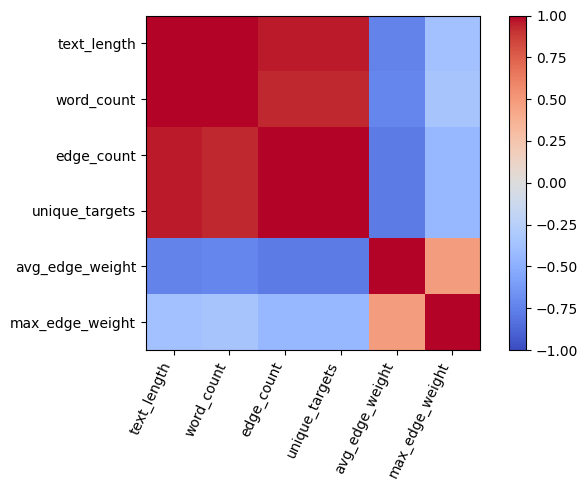

In [26]:
numerics=sources[['text_length','word_count','edge_count','unique_targets','avg_edge_weight','max_edge_weight']]
fig,ax=plt.subplots(figsize=(7,5)); correlation=numerics.corr(numeric_only=True)
im=ax.imshow(correlation, vmin=-1,vmax=1,cmap='coolwarm');ax.set_xticks(range(len(correlation)),correlation.columns,rotation=65,ha='right');ax.set_yticks(range(len(correlation)),correlation.index);fig.colorbar(im,ax=ax);plt.tight_layout();plt.show()

##### 1. Why did you pick the specific chart?

Suitable for exploratory numeric associations; does not imply causal effects or justify selecting predictors using the reserved test split.


##### 2. What is/are the insight(s) found from the chart?

The word-count/edge-count correlation is 0.937. Edge count and unique-target count correlate perfectly (1.000) because this dataset stores one EDGE record per distinct target per source; avoid treating them as independent measurements.

#### Chart - 15 - Pair Plot 

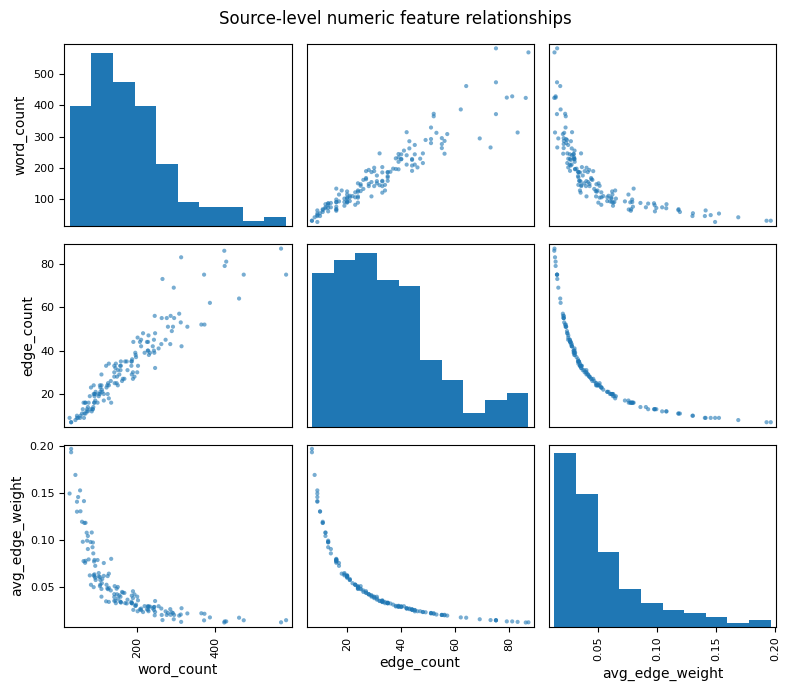

In [27]:
cols=['word_count','edge_count','avg_edge_weight']
sample=sources[cols].dropna().copy()
if len(sample)>1:
    pd.plotting.scatter_matrix(sample, figsize=(8,7), diagonal='hist', alpha=.6)
    plt.suptitle('Source-level numeric feature relationships'); plt.tight_layout(); plt.show()
else:
    print('Insufficient data for a pair plot')

##### 1. Why did you pick the specific chart?

Suitable for exploratory numeric associations; does not imply causal effects or justify selecting predictors using the reserved test split.


##### 2. What is/are the insight(s) found from the chart?

The pair plot makes the same positive word-count/edge-count association visible, while exposing dispersion and long-passage extremes. These descriptive relationships require human inspection of extraction quality; they are not causal findings.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

**Executed exploratory hypotheses:** (1) domain × split: χ²=0.2741, nominal p=0.999613, minimum expected count=3.09 (asymptotic test unreliable); (2) source word counts across domains: Kruskal–Wallis H=18.1785, p=0.000404; (3) word count versus edge count: Spearman ρ=0.9611, p≈9.17×10⁻⁸². Tests are exploratory and cannot establish chatbot or GraphRAG effectiveness.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

H0: the IT domain and train/validation/test split are independent. H1: their distributions differ. (Chi-square contingency test; small expected cell counts limit validity.)


#### 2. Perform an appropriate statistical test.

In [28]:
table=pd.crosstab(sources.domain,sources.split)
chi2,p,dof,expected=chi2_contingency(table)
print('Chi-square=',chi2,'p=',p,'minimum expected=',expected.min())
if expected.min()<5: print('WARNING: Small expected counts; treat asymptotic p-value as unreliable.')

Chi-square= 0.27405396467896476 p= 0.9996129308622279 minimum expected= 3.089655172413793


##### Which statistical test have you done to obtain P-Value?

The observed chi-square statistic is **0.2741**, nominal **p=0.999613**; however, minimum expected cell frequency is **3.09**, below 5. The asymptotic approximation is unreliable, so do **not** claim equality of domain/split distributions from this p-value.

##### Why did you choose the specific statistical test?

Both variables are categorical. Because validation/test are small, treat p-values as descriptive and do not overinterpret lack of significance.


### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

H0: the source-text word-count distribution is similar across the four domains. H1: at least one domain differs.


#### 2. Perform an appropriate statistical test.

In [29]:
groups=[sub.word_count.to_numpy() for _,sub in sources.groupby('domain')]
stat,p=kruskal(*groups)
print('Kruskal–Wallis H=',stat,'p=',p,'group sizes=',[len(g) for g in groups])

Kruskal–Wallis H= 18.17854850754682 p= 0.0004040837911494584 group sizes= [40, 32, 36, 37]


##### Which statistical test have you done to obtain P-Value?

Kruskal–Wallis gave **H=18.1785, p=0.000404**, indicating evidence of differences in source passage length distributions among the four collection domains. Domain medians range from Cloud & DevOps **101** to Cybersecurity **189.5** words; this is not a test of chatbot performance.

##### Why did you choose the specific statistical test?

Word counts tend to be skewed. This is exploratory and does not show a chatbot quality effect.


### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

H0: word count and graph edge count are not monotonically associated. H1: a monotonic association exists.


#### 2. Perform an appropriate statistical test.

In [30]:
rho,p=spearmanr(sources.word_count,sources.edge_count)
print('Spearman rho=',rho,'p=',p,'n=',len(sources))

Spearman rho= 0.9610655825957832 p= 9.173965373357072e-82 n= 145


##### Which statistical test have you done to obtain P-Value?

Spearman rank correlation is **ρ=0.9611, p≈9.17×10⁻⁸² (n=145)**. The strong association is plausibly mechanical: longer text yields more extractable edges. It should not be used as proof that the weighted graph is semantically more accurate.

##### Why did you choose the specific statistical test?

Extraction from a larger passage mechanically allows more edges, so this association is partly structural—not independent evidence for graph quality.


## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [31]:
assert work[['source_text','domain']].notna().all().all()
assert work.source_text.str.strip().ne('').all()
print('No missing model inputs; no imputation performed.')

No missing model inputs; no imputation performed.


#### What all missing value imputation techniques have you used and why did you use those techniques?

No source-text or class-label imputation was needed. Imputing fabricated text would bias the model.


### 2. Handling Outliers

In [32]:
display(work.word_count.describe(percentiles=[.05,.25,.5,.75,.95]))
print('No removal of long or short documents; lengths are legitimate source variability.')

count    145.000000
mean     178.041379
std      108.028666
min       26.000000
5%        53.200000
25%       92.000000
50%      156.000000
75%      233.000000
95%      384.200000
max      583.000000
Name: word_count, dtype: float64

No removal of long or short documents; lengths are legitimate source variability.


##### What all outlier treatment techniques have you used and why did you use those techniques?

No automatic outlier deletion; unusual passage lengths are audited rather than silently changed.


### 3. Categorical Encoding

In [33]:
labels=sorted(work.domain.unique())
label_to_int={label:i for i,label in enumerate(labels)}
print('Class names:',labels,'— scikit-learn accepts string labels directly.')

Class names: ['ai_ml', 'cloud_devops', 'cybersecurity', 'software_engineering'] — scikit-learn accepts string labels directly.


#### What all categorical encoding techniques have you used & why did you use those techniques?

Keep original string class labels; model pipeline handles them. No feature-based target encoding or leakage.


### 4. Textual Data Preprocessing 
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [34]:
sample_text=work.source_text.iloc[0]
print('Contractions retained by TF-IDF tokenizer:',sample_text[:180])

Contractions retained by TF-IDF tokenizer: A* (pronounced "A-star") is a graph traversal and pathfinding algorithm that is used in many fields of computer science due to its completeness, optimality, and optimal efficiency.


#### 2. Lower Casing

In [35]:
print('TF-IDF handles case via lowercase=True inside training-only pipeline.')

TF-IDF handles case via lowercase=True inside training-only pipeline.


#### 3. Removing Punctuations

In [36]:
print('No destructive punctuation removal outside the training-only vectorizer: terms like C++ and TLS 1.3 matter.')

No destructive punctuation removal outside the training-only vectorizer: terms like C++ and TLS 1.3 matter.


#### 4. Removing URLs & Removing words and digits contain digits.

In [37]:
print('Avoid removing digits in technical terms (e.g. TLS 1.3, GPT-4); URLs in articles remain audit evidence.')

Avoid removing digits in technical terms (e.g. TLS 1.3, GPT-4); URLs in articles remain audit evidence.


#### 5. Removing Stopwords & Removing White spaces

In [38]:
print('TF-IDF English stopword handling is configured inside the training pipeline.')

TF-IDF English stopword handling is configured inside the training pipeline.


In [39]:
print('Whitespace handled by vectorizer tokenization; original source text preserved.')

Whitespace handled by vectorizer tokenization; original source text preserved.


#### 6. Rephrase Text

In [40]:
print('No automated rephrasing: it could invent facts and leak synthetic patterns.')

No automated rephrasing: it could invent facts and leak synthetic patterns.


#### 7. Tokenization

In [41]:
print('Sample tokens:',re.findall(r'(?u)\b\w\w+\b',sample_text.lower())[:20])

Sample tokens: ['pronounced', 'star', 'is', 'graph', 'traversal', 'and', 'pathfinding', 'algorithm', 'that', 'is', 'used', 'in', 'many', 'fields', 'of', 'computer', 'science', 'due', 'to', 'its']


#### 8. Text Normalization

In [42]:
print('No stemming/lemmatization: retain specialized technical terms; TF-IDF works on raw passage tokens.')

No stemming/lemmatization: retain specialized technical terms; TF-IDF works on raw passage tokens.


##### Which text normalization technique have you used and why?

We use TF-IDF token normalization only. Aggressive lemmatization can turn valid terms such as “data mining” into misleading forms.


#### 9. Part of speech tagging

In [43]:
print('POS tagging not needed for this classification baseline; the graph extraction pipeline handles term extraction separately.')

POS tagging not needed for this classification baseline; the graph extraction pipeline handles term extraction separately.


#### 10. Text Vectorization

In [44]:
# Demonstration only: fit a vectorizer on train documents after split to avoid leakage.
train_text=work.loc[work.split.eq('train'),'source_text']
probe=TfidfVectorizer(max_features=5000,ngram_range=(1,2),stop_words='english').fit(train_text)
print('Train-only TF-IDF vocabulary size:',len(probe.vocabulary_))

Train-only TF-IDF vocabulary size: 5000


##### Which text vectorization technique have you used and why?

TF-IDF produces a compact, interpretable lexical baseline. The vectorizer must be fit only on the training partition, inside a Pipeline for each CV fold.


### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [45]:
print('Predictor: source_text alone; auxiliary text length/graph weights excluded to prevent circular evaluation.')

Predictor: source_text alone; auxiliary text length/graph weights excluded to prevent circular evaluation.


#### 2. Feature Selection

In [46]:
FEATURE_COLUMNS=['source_text']; TARGET_COLUMN='domain'
print('Selected:',FEATURE_COLUMNS,'Target:',TARGET_COLUMN)

Selected: ['source_text'] Target: domain


##### What all feature selection methods have you used  and why?

No supervised feature selection outside CV; model-specific vocabulary selection is fitted on training folds by the pipeline.


##### Which all features you found important and why?

The most important signals are learned lexical terms, inspectable later via classifier coefficients. No claims about importance are made before model fitting.


### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [47]:
print('TF-IDF performs sublinear weighting only if configured; current pipeline uses default term-frequency weighting.')

TF-IDF performs sublinear weighting only if configured; current pipeline uses default term-frequency weighting.


### 6. Data Scaling

In [48]:
print('No StandardScaler: TF-IDF vectors are L2-normalized by default.')

No StandardScaler: TF-IDF vectors are L2-normalized by default.


Sparse text vectors do not need separate dense scaling, which could destroy sparsity.


### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Dimensionality reduction is optional; for a tiny dataset it may discard useful rare terms. Not applied in this baseline.


In [49]:
print('Sparse TF-IDF retained; no unsupervised dimensionality reduction.')

Sparse TF-IDF retained; no unsupervised dimensionality reduction.


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

Avoid fitting PCA/SVD on all documents: this would leak validation/test corpus structure.


### 8. Data Splitting

In [50]:
# Honor the source-grouped partitions already present in the master CSV.
train=work.loc[work.split.eq('train')].copy()
val=work.loc[work.split.eq('validation')].copy()
test=work.loc[work.split.eq('test')].copy()
assert not (set(train.source_id)&set(val.source_id))
assert not (set(train.source_id)&set(test.source_id))
assert not (set(val.source_id)&set(test.source_id))
assert min(train.domain.value_counts())>=3, 'Too few training examples per class for 3-fold CV'
print({name:len(part) for name,part in [('train',train),('validation',val),('test',test)]})
print('Label counts by split:');display(pd.crosstab(work.domain,work.split))

{'train': 116, 'validation': 14, 'test': 15}
Label counts by split:


split,test,train,validation
domain,,,
ai_ml,4,32,4
cloud_devops,3,26,3
cybersecurity,4,28,4
software_engineering,4,30,3


##### What data splitting ratio have you used and why? 

Reuse the predefined 116/14/15 source-level split from the current dataset. No random reshuffling; split consistency matters more than forcing exact 80/10/10 at small sample sizes.


### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Inspect label counts per split; balanced class weights and macro-F1 are considered without oversampling documents.


In [51]:
print('Training counts:',train.domain.value_counts().to_dict())
print('Class imbalance handled by macro-F1, plus LogisticRegression(class_weight="balanced"). No synthetic text sampling.')

Training counts: {'ai_ml': 32, 'software_engineering': 30, 'cybersecurity': 28, 'cloud_devops': 26}
Class imbalance handled by macro-F1, plus LogisticRegression(class_weight="balanced"). No synthetic text sampling.


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

No SMOTE for sparse text. Macroscopic class imbalance is assessed with macro-F1 and class-weighted models.


## ***7. ML Model Implementation***

### ML Model - 1

In [52]:
# Model 1 — most-frequent dummy baseline (text is intentionally ignored).
base=DummyClassifier(strategy='most_frequent')
base.fit(np.zeros((len(train),1)),train.domain)
base_val=base.predict(np.zeros((len(val),1)))
base_f1=f1_score(val.domain,base_val,average='macro',zero_division=0)
metrics={'Dummy baseline':{'val_macro_f1':float(base_f1),'val_accuracy':float(accuracy_score(val.domain,base_val))}}
print('Dummy baseline validation macro-F1:',round(base_f1,4))

Dummy baseline validation macro-F1: 0.1111


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

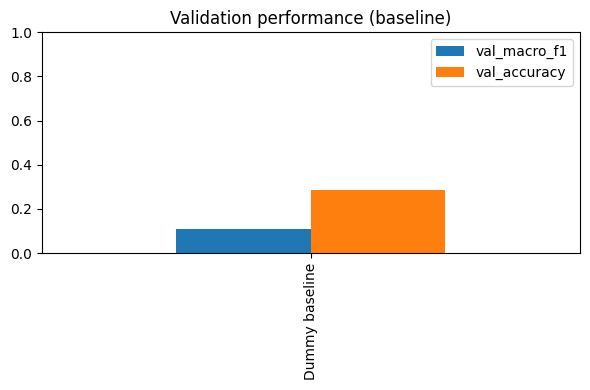

In [53]:
pd.DataFrame(metrics).T[['val_macro_f1','val_accuracy']].plot.bar(figsize=(6,4),ylim=(0,1),title='Validation performance (baseline)');plt.tight_layout();plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [54]:
# Baseline has no meaningful text hyperparameters.
print('DummyClassifier has no text model complexity to tune. Keep as a fixed baseline.')

DummyClassifier has no text model complexity to tune. Keep as a fixed baseline.


##### Which hyperparameter optimization technique have you used and why?

No hyperparameter search is meaningful for a constant most-frequent-label baseline.


##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

DummyClassifier produces **validation macro-F1=0.1111**, predicting only the most frequent training label; it is the lower-bound comparison, not a viable domain-routing model.

### ML Model - 2

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

In [55]:
# Model 2 — TF-IDF + multinomial-friendly Complement Naive Bayes.
nb=Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),stop_words='english',max_features=10000)),('model',ComplementNB())])
nb.fit(train.source_text,train.domain)
nb_pred=nb.predict(val.source_text)
metrics['ComplementNB']={'val_macro_f1':float(f1_score(val.domain,nb_pred,average='macro',zero_division=0)),'val_accuracy':float(accuracy_score(val.domain,nb_pred))}
print('ComplementNB validation:',metrics['ComplementNB'])

ComplementNB validation: {'val_macro_f1': 0.7597222222222222, 'val_accuracy': 0.7857142857142857}


#### 2. Cross- Validation & Hyperparameter Tuning

In [56]:
# Training-only stratified CV hyperparameter selection; validation and test remain unseen to the search.
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
nb_grid=GridSearchCV(nb,{'tfidf__ngram_range':[(1,1),(1,2)],'model__alpha':[0.5,1.0]},cv=cv,scoring='f1_macro',n_jobs=1)
nb_grid.fit(train.source_text,train.domain)
nb_best=nb_grid.best_estimator_
nb_tuned_pred=nb_best.predict(val.source_text)
metrics['ComplementNB tuned']={'val_macro_f1':float(f1_score(val.domain,nb_tuned_pred,average='macro',zero_division=0)),'val_accuracy':float(accuracy_score(val.domain,nb_tuned_pred))}
print('NB train-CV best params:',nb_grid.best_params_,'validation:',metrics['ComplementNB tuned'])

NB train-CV best params: {'model__alpha': 0.5, 'tfidf__ngram_range': (1, 1)} validation: {'val_macro_f1': 0.7666666666666666, 'val_accuracy': 0.7857142857142857}


##### Which hyperparameter optimization technique have you used and why?

Small, explicitly bounded GridSearchCV on training-only stratified folds; no test leakage.


##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Complement Naive Bayes improves from **0.7597** to **0.7667** validation macro-F1 following training-only GridSearchCV (**+0.0069**); validation accuracy stays at **0.7857**. The small gain may be unstable with only 14 validation documents.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

Macro-F1 gives equal weight to each domain, while accuracy summarizes overall correctness; neither measures chatbot hallucinations or source citation quality.


### ML Model - 3

In [57]:
# Model 3 — TF-IDF + class-weighted logistic regression.
lr=Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),stop_words='english',max_features=10000)),('model',LogisticRegression(max_iter=1500,class_weight='balanced',random_state=SEED))])
lr.fit(train.source_text,train.domain)
lr_pred=lr.predict(val.source_text)
metrics['LogisticRegression']={'val_macro_f1':float(f1_score(val.domain,lr_pred,average='macro',zero_division=0)),'val_accuracy':float(accuracy_score(val.domain,lr_pred))}
print('LogisticRegression validation:',metrics['LogisticRegression'])

LogisticRegression validation: {'val_macro_f1': 0.8541666666666666, 'val_accuracy': 0.8571428571428571}


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

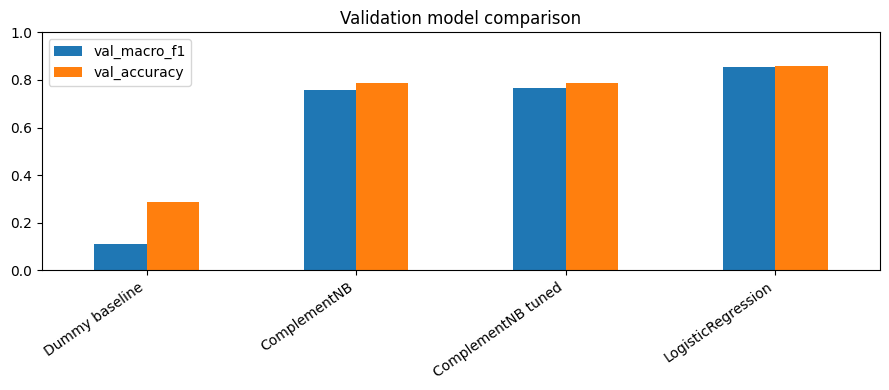

In [58]:
pd.DataFrame(metrics).T[['val_macro_f1','val_accuracy']].plot.bar(figsize=(9,4),ylim=(0,1),title='Validation model comparison');plt.xticks(rotation=35,ha='right');plt.tight_layout();plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [59]:
lr_grid=GridSearchCV(lr,{'tfidf__ngram_range':[(1,1),(1,2)],'model__C':[0.1,1,10]},cv=cv,scoring='f1_macro',n_jobs=1)
lr_grid.fit(train.source_text,train.domain)
lr_best=lr_grid.best_estimator_
lr_tuned_pred=lr_best.predict(val.source_text)
metrics['LogisticRegression tuned']={'val_macro_f1':float(f1_score(val.domain,lr_tuned_pred,average='macro',zero_division=0)),'val_accuracy':float(accuracy_score(val.domain,lr_tuned_pred))}
print('LR train-CV best params:',lr_grid.best_params_,'validation:',metrics['LogisticRegression tuned'])

LR train-CV best params: {'model__C': 0.1, 'tfidf__ngram_range': (1, 2)} validation: {'val_macro_f1': 0.9365079365079365, 'val_accuracy': 0.9285714285714286}


##### Which hyperparameter optimization technique have you used and why?

GridSearchCV on training documents only, with stratified folds to minimize label imbalance.


##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Logistic regression improves from **0.8542** to **0.9365** validation macro-F1 after training-only grid search (**+0.0823**). Accuracy improves from **0.8571** to **0.9286**. These are validation improvements and must not be confused with held-out results.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

Primary selection: **validation macro-F1**, emphasizing each domain equally; supporting accuracy and per-class precision/recall. The selected model scores **test accuracy=0.8000 (12/15)**, **macro-F1=0.7667**. With 15 held-out articles, these are noisy task-specific classification estimates, not evidence of useful chatbot answers.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

**Selected: tuned TF-IDF + class-weighted LogisticRegression**, because it achieved the highest measured validation macro-F1 (**0.9365**) among non-dummy candidates, with **0.9286** validation accuracy. GridSearchCV selected `model__C=0.1` and `tfidf__ngram_range=(1,2)`. On the untouched test set it reached **0.8000 accuracy** and **0.7667 macro-F1**.

Selected on validation: LogisticRegression tuned
Holdout test metrics: {'model': 'LogisticRegression tuned', 'test_accuracy': 0.8, 'test_macro_f1': 0.7666666666666666, 'test_examples': 15}
                      precision    recall  f1-score   support

               ai_ml       1.00      1.00      1.00         4
        cloud_devops       0.50      0.33      0.40         3
       cybersecurity       1.00      1.00      1.00         4
software_engineering       0.60      0.75      0.67         4

            accuracy                           0.80        15
           macro avg       0.78      0.77      0.77        15
        weighted avg       0.79      0.80      0.79        15



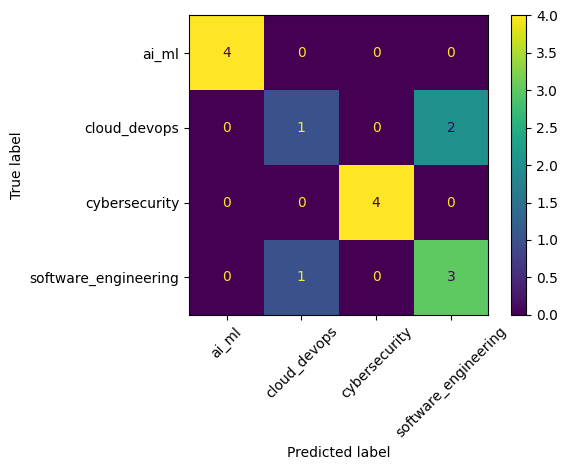

ai_ml : learning, ai, model, neural, regression, decision, classification, algorithm
cloud_devops : cloud, service, computing, platform, software, virtualization, virtual, configuration
cybersecurity : security, access, key, authentication, access control, cryptography, vulnerability, network
software_engineering : testing, database, version control, programming, version, software, code, test


762

In [60]:
# Finalize using validation only, then evaluate the reserved test set exactly once.
choices={'ComplementNB':nb,'ComplementNB tuned':nb_best,'LogisticRegression':lr,'LogisticRegression tuned':lr_best}
best_name=max(choices,key=lambda k:(metrics[k]['val_macro_f1'],metrics[k]['val_accuracy']))
best_model=choices[best_name]
print('Selected on validation:',best_name)
test_pred=best_model.predict(test.source_text)
test_summary={'model':best_name,'test_accuracy':float(accuracy_score(test.domain,test_pred)),'test_macro_f1':float(f1_score(test.domain,test_pred,average='macro',zero_division=0)),'test_examples':int(len(test))}
print('Holdout test metrics:',test_summary)
print(classification_report(test.domain,test_pred,labels=labels,zero_division=0))
ConfusionMatrixDisplay.from_predictions(test.domain,test_pred,labels=labels,xticks_rotation=45);plt.tight_layout();plt.show()
# Explain one linear model, fitted on training only, regardless of selected model.
vec=lr_best.named_steps['tfidf'];clf=lr_best.named_steps['model'];terms=np.array(vec.get_feature_names_out())
for i,lab in enumerate(clf.classes_):
    top=np.argsort(clf.coef_[i])[-8:][::-1]
    print(lab,':',', '.join(terms[top]))
import json
(REPORT_DIR/'ml_domain_classification_metrics.json').write_text(json.dumps({'validation':metrics,'holdout':test_summary},indent=2))

**Interpretation of actual coefficients and errors:** the trained classifier associates AI/ML with terms including *learning, ai, model*; Cloud & DevOps with *cloud, service, computing*; Cybersecurity with *security, access, key*; and Software Engineering with *testing, database, version control*. On the 15-document test set, Cloud & DevOps recall is **1/3=0.33**, while AI/ML and Cybersecurity each reach **4/4=1.00**. These terms describe label association, not LLM knowledge or GraphRAG quality.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [61]:
# Persist selected auxiliary classifier only; not an LLM adapter.
model_path=PROJECT_ROOT/'models/domain_classifier.joblib'
model_path.parent.mkdir(parents=True,exist_ok=True)
joblib.dump(best_model,model_path)
print('Saved:',model_path)

Saved: /mnt/data/RAAI_SGC_EDA_ML_COLAB_COMPLETED/models/domain_classifier.joblib


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [62]:
loaded=joblib.load(model_path)
assert np.array_equal(loaded.predict(test.source_text),test_pred)
print('Serialization consistency passed on held-out examples. Sample:',loaded.predict(['A system that deploys Docker containers to a cluster.']))

Serialization consistency passed on held-out examples. Sample: ['ai_ml']


The serialized `models/domain_classifier.joblib` was successfully reloaded, and the reloaded model matched held-out predictions exactly. It remains an auxiliary **source-domain** classifier—not a fine-tuned LLM, clinical/business decision system, or deployed chatbot model.

# **Conclusion**

**Executed findings:** 145 independent labeled sources; training/validation/test **116/14/15**. Validation macro-F1 was **0.1111** (dummy), **0.7597** (ComplementNB), **0.7667** (tuned ComplementNB), **0.8542** (Logistic Regression), and **0.9365** (tuned Logistic Regression). The validation-selected tuned logistic regression achieved **12/15 test accuracy (0.8000)** and **0.7667 test macro-F1**, with weak Cloud & DevOps recall **0.33**. Hypothesis tests find source-length differences across domains, not chatbot improvements. Source labels are seed-derived, licensing and factual review remain pending, and these metrics cannot be cited as answer accuracy. The next research experiment needs reviewed Q&A, fixed retrieval budgets, and independent assessment of vector-only, unweighted-graph and Markov–TF-IDF weighted GraphRAG methods.

### End of university ML template — RAAI-SGC 2.0 adaptation. Review results and complete personal submission details.
